In [1]:
# !pip install reservoirpy
import pathlib
import tensorflow as tf
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import keras
from keras import layers, models, initializers, backend as K
from sklearn.metrics import confusion_matrix
import seaborn as sns
# import reservoirpy as rpy
from concurrent.futures import ProcessPoolExecutor
# from google.colab import drive
from scipy.spatial.distance import pdist, squareform
# drive.mount('/content/drive/')

2025-02-07 02:24:00.013330: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-02-07 02:24:00.122365: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1738891440.174029  723885 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1738891440.189007  723885 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-07 02:24:00.282353: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

### Data, Preprocessing, Utils

In [ ]:
%%shell

wget http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
mkdir speech_commands
tar -xzf speech_commands_v0.02.tar.gz -C speech_commands

--2024-11-03 15:17:04--  http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
Resolving download.tensorflow.org (download.tensorflow.org)... 142.251.170.207, 173.194.174.207, 74.125.23.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|142.251.170.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2428923189 (2.3G) [application/gzip]
Saving to: ‘speech_commands_v0.02.tar.gz’

speech_commands_v0. 100%[===================>]   2.26G  28.9MB/s    in 81s     

2024-11-03 15:18:25 (28.7 MB/s) - ‘speech_commands_v0.02.tar.gz’ saved [2428923189/2428923189]



In [2]:
# general settings for data, labels and mel spectrograms

dataset_path = "drive/MyDrive/Colab Notebooks/HDA/Data/speech_commands"
dirlist = np.array(os.listdir(dataset_path))
exlist = np.array(['_background_noise_', '.DS_Store', 'README.md', 'LICENSE', 'testing_list.txt', 'validation_list.txt'])
wordlist = np.setdiff1d(dirlist, exlist)

full_dataset = False
filter = True
forests = False
labels = ['down', 'go']#, 'left', 'no']#, 'right', 'stop', 'up', 'yes']
if full_dataset:
  labels = wordlist

lab2int = {label: i for i, label in enumerate(labels)}
int2lab = {i: label for i, label in enumerate(labels)}



sr = 16000
n_mels = 24
win_length=int(sr*0.06)
hop_length=int(sr*0.04)


In [3]:
def process_audio_file(filepath, label, filter=filter, filter_length=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length):

    audio, sr = librosa.load(filepath, sr=16000)
    length = len(audio)

    # Apply filtering based on length
    if filter and length < filter_length:
        return None  # Skip this file if it doesn't meet the length criteria

    # Padding if necessary
    if length < filter_length:
        padded = np.zeros(filter_length)
        start = (filter_length - length) // 2
        end = start + length
        padded[start:end] = audio
        audio = padded

    audio = librosa.util.normalize(audio)
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length)
    mel = librosa.power_to_db(mel, ref=np.max)

    return mel, label

# Prepare to collect results
X = []
l = []

# Main processing
with ProcessPoolExecutor() as executor:
    futures = []
    for label in labels:
        label_path = os.path.join(dataset_path, label)
        for filename in os.listdir(label_path):
            if filename.endswith(".wav"):
                filepath = os.path.join(label_path, filename)
                futures.append(executor.submit(process_audio_file, filepath, label))

    # Collect results
    for future in futures:
        result = future.result()
        if result is not None:
            mel, label = result
            X.append(mel)
            l.append(label)


In [ ]:
# for label in labels:
#   label_path = os.path.join(dataset_path, label)
#   for filename in os.listdir(label_path):
#     if filename.endswith(".wav"):
#       filepath = os.path.join(label_path, filename)
#       audio, sr = librosa.load(filepath, sr=16000)
#       length = len(audio)
#       if filter and length < 16000:
#         continue

#       elif length < 16000:
#         padded = np.zeros(16000)
#         start = (16000 - length)//2
#         end = start + length
#         padded[start:end] = audio
#         audio = padded

#       audio = librosa.util.normalize(audio)
#       mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length)
#       mel = librosa.power_to_db(mel,ref=np.max)
#       X.append(mel)
#       l.append(label) ###TBD

In [4]:
X = np.array(X)
l = np.array(l)

X_inv = X.transpose(0,1,2)
# np.array([x.T for x in X]) ###TBD
n_feat = X_inv.shape[1]
n_times = X_inv.shape[2]

if forests:
  X_inv = X.reshape(X.shape[0], -1)

y = np.array([lab2int[label] for label in l])

X_train, X_test, y_train, y_test = train_test_split(X_inv, y, test_size=0.3)#, random_state=42)

print(X_inv.shape)

(7058, 24, 26)


## models

### 1. random forests


In [ ]:
clf = RandomForestClassifier(n_estimators=200)
clf.fit(X_train, y_train)

# # Make predictions on the test set
y_pred = clf.predict(X_test)

# # Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.8895184135977338


In [ ]:
print("Accuracy:", accuracy)

Accuracy: 0.8269230769230769


### 2. RNN

In [ ]:
nnodes = 40

input_layer = layers.Input(shape=(n_feat, n_times))
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(input_layer)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
# x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
# x = layers.SimpleRNN(nnodes, return_sequences=True, activation="relu", dropout=0.)(x)
x = layers.SimpleRNN(nnodes, return_sequences=False, activation="relu", dropout=0.)(x)
x = layers.Dropout(0.)(x)
output_layer = layers.Dense(len(labels), activation="softmax")(x)

my_Recurrent_classifier = models.Model(input_layer, output_layer)
my_Recurrent_classifier.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 26, 24)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_5 (SimpleRNN)             │ (None, 26, 40)              │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_6 (SimpleRNN)             │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_7 (SimpleRNN)             │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_8 (SimpleRNN)             │ (None, 26, 40)              │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_9 (SimpleRNN)             │ (None, 40)                  │           3,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 40)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             328 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,888 (62.06 KB)

 Trainable params: 15,888 (62.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
my_Recurrent_classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = my_Recurrent_classifier.fit(X_train, y_train, epochs=40, validation_data=(X_test, y_test), verbose=1, batch_size=32)

Epoch 1/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.2034 - loss: 4.8007 - val_accuracy: 0.3190 - val_loss: 1.7244
Epoch 2/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 33s 54ms/step - accuracy: 0.4437 - loss: 1.4127 - val_accuracy: 0.5164 - val_loss: 1.2696
Epoch 3/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 34s 42ms/step - accuracy: 0.6185 - loss: 0.9912 - val_accuracy: 0.6998 - val_loss: 0.7974
Epoch 4/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 62s 77ms/step - accuracy: 0.6698 - loss: 0.8544 - val_accuracy: 0.6870 - val_loss: 0.8151
Epoch 5/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 26s 43ms/step - accuracy: 0.7002 - loss: 0.7937 - val_accuracy: 0.7299 - val_loss: 0.7522
Epoch 6/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 26s 43ms/step - accuracy: 0.7448 - loss: 0.6789 - val_accuracy: 0.7297 - val_loss: 0.7310
Epoch 7/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 43s 45ms/step - accuracy: 0.7413 - loss: 0.7112 - val_accuracy: 0.7729 - val_loss: 0.6482
Epoch 8/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 39s 43ms/step - accuracy: 0.7551 - loss: 0.6740 - 

###3. Reservoir(ESN)

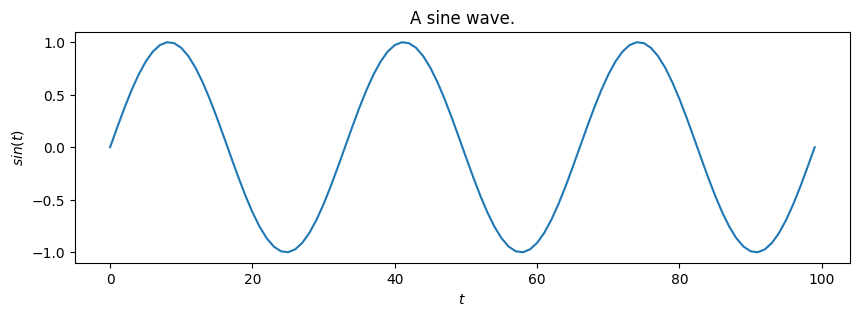

New state vector shape:  (1, 100)


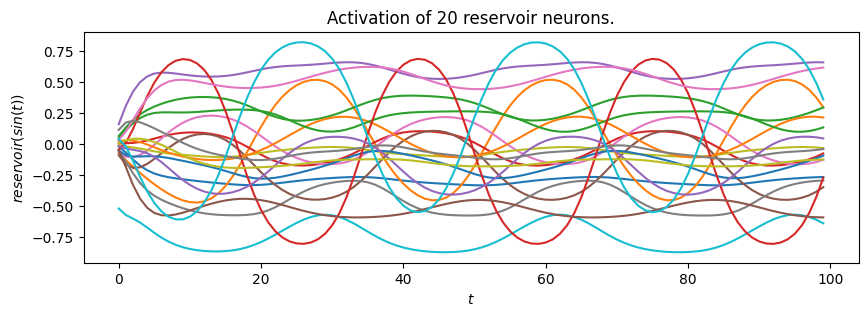

In [ ]:
import reservoirpy as rpy

rpy.verbosity(0)  # no need to be too verbose here
rpy.set_seed(42)  # make everything reproducible!
from reservoirpy.nodes import Reservoir

reservoir = Reservoir(100, lr=0.5, sr=0.9)

import numpy as np
import matplotlib.pyplot as plt

X = np.sin(np.linspace(0, 6*np.pi, 100)).reshape(-1, 1)

# plt.figure(figsize=(10, 3))
# plt.title("A sine wave.")
# plt.ylabel("$sin(t)$")
# plt.xlabel("$t$")
# plt.plot(X)
plt.show()

s = reservoir(X[0].reshape(1, -1))

print("New state vector shape: ", s.shape)

s = reservoir.state()

states = np.empty((len(X), reservoir.output_dim))
for i in range(len(X)):
    states[i] = reservoir(X[i].reshape(1, -1))

# plt.figure(figsize=(10, 3))
# plt.title("Activation of 20 reservoir neurons.")
# plt.ylabel("$reservoir(sin(t))$")
# plt.xlabel("$t$")
# plt.plot(states[:, :20])
# plt.show()

states = reservoir.run(X)

# from reservoirpy.nodes import Reservoir, Ridge, FORCE, ESN

# reservoir = reservoir.reset()

# states_from_null = reservoir.run(X, reset=True)

# a_state_vector = np.random.uniform(-1, 1, size=(1, reservoir.output_dim))

# states_from_a_starting_state = reservoir.run(X, from_state=a_state_vector)

# previous_states = reservoir.run(X)

# with reservoir.with_state(reset=True):
#     states_from_null = reservoir.run(X)

# # as if the with_state never happened!
# states_from_previous = reservoir.run(X)
# #######



# # from reservoirpy.nodes import Ridge

# # readout = Ridge(ridge=1e-7)

# # X_train = X[:50]
# # Y_train = X[1:51]

# # plt.figure(figsize=(10, 3))
# # plt.title("A sine wave and its future.")
# # plt.xlabel("$t$")
# # plt.plot(X_train, label="sin(t)", color="blue")
# # plt.plot(Y_train, label="sin(t+1)", color="red")
# # plt.legend()
# # plt.show()


# # train_states = reservoir.run(X_train, reset=True)

# # readout = readout.fit(train_states, Y_train, warmup=10)

# # test_states = reservoir.run(X[50:])
# # Y_pred = readout.run(test_states)

# # plt.figure(figsize=(10, 3))
# # plt.title("A sine wave and its future.")
# # plt.xlabel("$t$")
# # plt.plot(Y_pred, label="Predicted sin(t)", color="blue")
# # plt.plot(X[51:], label="Real sin(t+1)", color="red")
# # plt.legend()
# # plt.show()








# # # from reservoirpy.nodes import Reservoir, Ridge

# # # reservoir = Reservoir(100, lr=0.5, sr=0.9)
# # # readout = Ridge(ridge=1e-7)

# # # esn_model = reservoir >> readout

# # # esn_model = esn_model.fit(X_train, Y_train, warmup=10)

# # # print(reservoir.is_initialized, readout.is_initialized, readout.fitted)

# # # Y_pred = esn_model.run(X[50:])

# # # plt.figure(figsize=(10, 3))
# # # plt.title("A sine wave and its future.")
# # # plt.xlabel("$t$")
# # # plt.plot(Y_pred, label="Predicted sin(t+1)", color="blue")
# # # plt.plot(X[51:], label="Real sin(t+1)", color="red")
# # # plt.legend()
# # # plt.show()

In [ ]:
# my_reservoir = rpy.nodes.Reservoir(100, lr=0.5, sr=0.9)

# my_data = np.random.random(size = (1000,70,10))

mapped = np.array([my_reservoir.run(x) for x in my_data])



In [ ]:
m0 = mapped[0]

In [ ]:
np.sum(m0 == mapped[0])

0

In [ ]:
X_train.shape

In [89]:
reser = rpy.nodes.Reservoir(50, lr=0.5, sr=0.7)

state_evo = []
# np.tile(y_train, (5))
for x in X_train:
  reser.reset()
  lastates = reser.run(x)[:,-10:]
  state_evo += [lastates[:,i:i+5] for i in range(5)]




Running Reservoir-2: 100%|██████████| 24/24 [00:00<00:00, 6515.85it/s]


In [15]:
np.repeat(y_train,5)[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

In [5]:
y_train.shape

(4940,)

In [7]:
y_train[:20]

array([1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0])

In [93]:
# from sklearn.linear_model import Ridge
# how do I fit a function that maps state_evo to y_train?
state_evo = np.array(state_evo)
classifier = Ridge(1e-7)
classifier.fit(state_evo.reshape(len(y_train)*5, -1), np.repeat(y_train,5))

Ridge(alpha=1e-07)

In [94]:
classifier.score(state_evo.reshape(len(y_train)*5, -1), np.repeat(y_train,5))

0.02056416891098145

In [95]:

test = []
for x in X_test:
  reser.reset()
  test.append(reser.run(x)[:,-5:])

preds = np.array([classifier.predict(test_sample.reshape(1,-1)) for test_sample in test])

Running Reservoir-2: 100%|██████████| 24/24 [00:00<00:00, 2830.24it/s]


In [46]:
y_test[:20]

array([0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0])

In [52]:
np.sum(preds//1 == y_test)/len(y_test)

1043.070821529745

In [53]:
len(y_test)

2118

In [101]:
np.sum((np.round(preds).T == y_test).flatten())/len(y_test)

0.7129367327667611

In [100]:
test[0].shape

(24, 5)

In [81]:
reser.reset()
check = reser.run(X_train[0])

Running Reservoir-0: 100%|██████████| 24/24 [00:00<00:00, 3158.26it/s]


In [85]:
check[:,-10:].shape

(24, 10)

(array([  21.,   30.,   35.,   95.,  231., 1527.,   50.,   61.,   42.,
          26.]),
 array([-490.18866266, -392.73496727, -295.28127188, -197.82757649,
        -100.3738811 ,   -2.92018571,   94.53350968,  191.98720507,
         289.44090046,  386.89459585,  484.34829125]),
 <BarContainer object of 10 artists>)

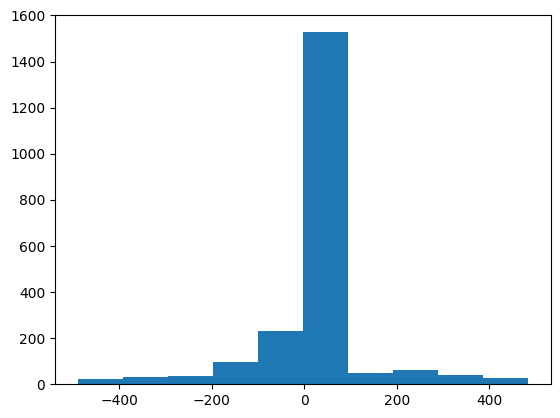

In [105]:
plt.hist(preds)